--- Initial Structural Inspection ---
Dataset Shape: 150 rows, 5 columns

--- Missing Value Summary Per Column ---
sepal_length    8
sepal_width     8
petal_length    8
petal_width     0
species         0
dtype: int64

Missing values remaining after cleaning: 0

--- Summary Statistics (Cleaned Dataset) ---
       sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean           5.82         3.05          3.79         1.20
std            0.80         0.43          1.73         0.76
min            4.30         2.00          1.00         0.10
25%            5.10         2.80          1.60         0.30
50%            5.80         3.00          4.40         1.30
75%            6.40         3.30          5.10         1.80
max            7.90         4.40          6.90         2.50

--- Correlation Matrix ---
              sepal_length  sepal_width  petal_length  petal_width
sepal_length          1.00        -0.12          0.82    

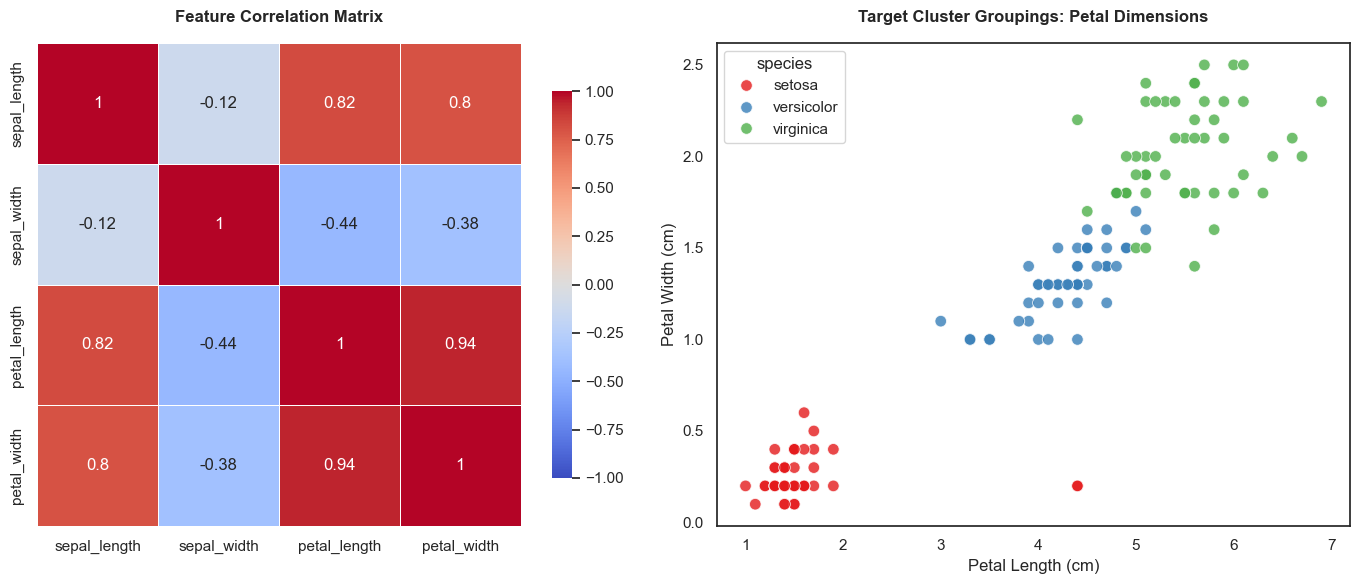

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load Real-World Dataset Layout (Injected with random missing values for demonstration)
np.random.seed(42)
iris = sns.load_dataset('iris')

# Inject synthetic missing values to demonstrate practical data handling
for col in ['sepal_length', 'sepal_width', 'petal_length']:
    iris.loc[iris.sample(frac=0.05).index, col] = np.nan

print("--- Initial Structural Inspection ---")
print(f"Dataset Shape: {iris.shape[0]} rows, {iris.shape[1]} columns\n")

# 2. Missing Value Detection & Remediation
print("--- Missing Value Summary Per Column ---")
missing_counts = iris.isnull().sum()
print(missing_counts)

# Handle missing numeric data by filling null positions with the column median
for col in iris.select_dtypes(include=[np.number]).columns:
    iris[col] = iris[col].fillna(iris[col].median())

print(f"\nMissing values remaining after cleaning: {iris.isnull().sum().sum()}")

# 3. Comprehensive Summary Statistics
print("\n--- Summary Statistics (Cleaned Dataset) ---")
print(iris.describe().round(2))

# 4. Correlation Matrix Extraction
# We drop the categorical 'species' column to calculate numeric relationships
numeric_df = iris.drop(columns=['species'])
correlation_matrix = numeric_df.corr()

print("\n--- Correlation Matrix ---")
print(correlation_matrix.round(2))

# 5. Visual Analysis Design
# Configure theme and prepare layout
sns.set_theme(style="white")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Correlation Matrix Heatmap
sns.heatmap(
    correlation_matrix, 
    annot=True,              # Write exact correlation coefficients inside blocks
    cmap='coolwarm',         # Diverging palette (blue = negative, red = positive correlation)
    vmin=-1, vmax=1,         # Anchor boundaries to the absolute correlation scale
    center=0,                # Neutral color mapped exactly to 0
    square=True,             # Maintain perfectly square cells
    linewidths=0.5,          # Distinct separation lines between blocks
    cbar_kws={"shrink": .8}, # Scale down side colorbar dimensions
    ax=axes[0]
)
axes[0].set_title('Feature Correlation Matrix', fontsize=12, fontweight='bold', pad=15)

# Subplot 2: Key Distribution Insights (Petal Dimensions by Species Group)
sns.scatterplot(
    data=iris, 
    x='petal_length', 
    y='petal_width', 
    hue='species', 
    palette='Set1', 
    s=70, 
    alpha=0.8, 
    ax=axes[1]
)
axes[1].set_title('Target Cluster Groupings: Petal Dimensions', fontsize=12, fontweight='bold', pad=15)
axes[1].set_xlabel('Petal Length (cm)')
axes[1].set_ylabel('Petal Width (cm)')

plt.tight_layout()
plt.show()
